#  Feature Engineering

---

1. Import packages
2. Load data
3. Feature engineering

---

## 1. Import packages

In [1]:
import pandas as pd
import numpy as np

---
## 2. Load data

In [2]:
# Use the dataframe loaded in the data-loading cell
df = pd.read_csv("/Users/israelasbanu/Downloads/clean_data_after_eda.csv")
print("Data Pelanggan: ",df.shape)


Data Pelanggan:  (14606, 44)


In [3]:
price_df = pd.read_csv('price_data.csv')
price_df["price_date"] = pd.to_datetime(price_df["price_date"], format='%Y-%m-%d')
price_df.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [4]:
# Remove colomn that only have 1 value

constant_cols = []
if not constant_cols:
    constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
df = df.drop(columns=constant_cols)
print(f"Dropped {len(constant_cols)} constant columns: {constant_cols}")

Dropped 0 constant columns: []


### Check for Highly Correlated Features

In [5]:
# Remove the column that almost similiar or having the corelation
import numpy as np

numeric_df = df.select_dtypes(include=[np.number])

corelation = numeric_df.corr().abs()

to_drop = set()

for i, col1 in enumerate(corelation.columns):
    for col2 in corelation.columns[i+1:]:
        if corelation.loc[col1, col2] > 0.98:
            to_drop.add(col2)

print("Similiar Column / Redundant:", sorted(to_drop))

#df = df.drop(columns=to_drop)

Similiar Column / Redundant: ['margin_net_pow_ele', 'var_6m_price_mid_peak', 'var_6m_price_off_peak', 'var_6m_price_peak', 'var_year_price_mid_peak', 'var_year_price_off_peak', 'var_year_price_peak']


# Feature Engineering

### 3.1 Date preparation

In [6]:
# Read Data

df = pd.read_csv("/Users/israelasbanu/Downloads/clean_data_after_eda.csv")

print("Shape:", df.shape)
print("Columns:", list(df.columns))

Shape: (14606, 44)
Columns: ['id', 'channel_sales', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'date_activ', 'date_end', 'date_modif_prod', 'date_renewal', 'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy', 'forecast_meter_rent_12m', 'forecast_price_energy_off_peak', 'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 'has_gas', 'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act', 'net_margin', 'num_years_antig', 'origin_up', 'pow_max', 'var_year_price_off_peak_var', 'var_year_price_peak_var', 'var_year_price_mid_peak_var', 'var_year_price_off_peak_fix', 'var_year_price_peak_fix', 'var_year_price_mid_peak_fix', 'var_year_price_off_peak', 'var_year_price_peak', 'var_year_price_mid_peak', 'var_6m_price_off_peak_var', 'var_6m_price_peak_var', 'var_6m_price_mid_peak_var', 'var_6m_price_off_peak_fix', 'var_6m_price_peak_fix', 'var_6m_price_mid_peak_fix', 'var_6m_price_off_peak', 'var_6m_price_peak', 'var_6m_price_mid_peak', 'churn']


In [7]:


# Read data
df = pd.read_csv("/Users/israelasbanu/Downloads/clean_data_after_eda.csv")

# Show basic data
print("Shape:", df.shape)
print("Columns:", list(df.columns))

# Saerch the correlation like column
date_like_cols = [c for c in df.columns if "date" in c.lower()]
print("\nKolom date-like:")
print(date_like_cols)

# Audit row date columns 
for col in date_like_cols:
    s = df[col]
    
    print(f"\n========================")
    print(f"COL: {col}")
    print(f"dtype awal: {s.dtype}")
    print("contoh value (raw):")
    print(s.head(10).tolist())
    
    # Missing raw
    print(f"missing_raw: {s.isna().sum()}")
    
    # Cek placeholder missing seperti 'MISSING', 'NA', 'N/A', 'null'
    placeholder_missing = s.astype(str).str.strip().str.lower().isin(["missing", "na", "n/a", "nan", "null", ""])
    print(f"placeholder_missing_count: {int(placeholder_missing.sum())}")
    
    # Parse date
    parsed = pd.to_datetime(s, errors="coerce")
    
    invalid_mask = s.notna() & parsed.isna()
    invalid_values = s[invalid_mask]
    
    print(f"invalid_count_after_parse: {int(invalid_values.shape[0])}")
    if not invalid_values.empty:
        print("invalid_examples:")
        print(invalid_values.head(10).tolist())
    
    print(f"min_date: {parsed.min()}")
    print(f"max_date: {parsed.max()}")
    print(f"n_unique: {s.nunique(dropna=True)}")
    
    # Cek apakah date implausible / future
    today = pd.Timestamp.now().normalize()
    future_mask = parsed.notna() & (parsed > today)
    print(f"future_date_count: {int(future_mask.sum())}")
    
    if future_mask.sum() > 0:
        print("future_examples:")
        print(s[future_mask].head(10).tolist())

# Validate the correlations between the Columns

df2 = df.copy()
for col in date_like_cols:
    df2[col] = pd.to_datetime(df2[col], errors="coerce")

print("\nHubungan antar tanggal (audit awal):")
for col in ["date_activ", "date_end", "date_renewal", "date_modif_prod"]:
    if col in df2.columns:
        print(f"{col}: min={df2[col].min()}, max={df2[col].max()}")

# check logis:
if "date_activ" in df2.columns and "date_end" in df2.columns:
    impossible_end_before_activ = (df2["date_end"] < df2["date_activ"]).sum()
    print(f"date_end < date_activ: {impossible_end_before_activ}")

if "date_activ" in df2.columns and "date_renewal" in df2.columns:
    impossible_renewal_before_activ = (df2["date_renewal"] < df2["date_activ"]).sum()
    print(f"date_renewal < date_activ: {impossible_renewal_before_activ}")

if "date_modif_prod" in df2.columns and "date_activ" in df2.columns:
    impossible_modif_before_activ = (df2["date_modif_prod"] < df2["date_activ"]).sum()
    print(f"date_modif_prod < date_activ: {impossible_modif_before_activ}")

Shape: (14606, 44)
Columns: ['id', 'channel_sales', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'date_activ', 'date_end', 'date_modif_prod', 'date_renewal', 'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy', 'forecast_meter_rent_12m', 'forecast_price_energy_off_peak', 'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 'has_gas', 'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act', 'net_margin', 'num_years_antig', 'origin_up', 'pow_max', 'var_year_price_off_peak_var', 'var_year_price_peak_var', 'var_year_price_mid_peak_var', 'var_year_price_off_peak_fix', 'var_year_price_peak_fix', 'var_year_price_mid_peak_fix', 'var_year_price_off_peak', 'var_year_price_peak', 'var_year_price_mid_peak', 'var_6m_price_off_peak_var', 'var_6m_price_peak_var', 'var_6m_price_mid_peak_var', 'var_6m_price_off_peak_fix', 'var_6m_price_peak_fix', 'var_6m_price_mid_peak_fix', 'var_6m_price_off_peak', 'var_6m_price_peak', 'var_6m_price_mid_peak', 'churn']

Kolo

#### Investigate 24 date columns

In [8]:
# Convert date column to datetime

date_cols = [
    "date_activ",
    "date_end",
    "date_modif_prod",
    "date_renewal"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Selecting rows where date_modif_prod is before date_activ

check = df[df["date_modif_prod"] < df["date_activ"]].copy()

# Calculating the day difference between both date

check["days_modif_before_activ"] = (
    check["date_activ"] - check["date_modif_prod"]
).dt.days

print("Counting the number of rows that need to be checked:", len(check))

print(
    check[
        [
            "id",
            "date_activ",
            "date_modif_prod",
            "days_modif_before_activ",
            "date_renewal",
            "date_end",
            "churn"
        ]
    ].sort_values("days_modif_before_activ").to_string(index=False)
)

Counting the number of rows that need to be checked: 24
                              id date_activ date_modif_prod  days_modif_before_activ date_renewal   date_end  churn
137a685dcfba3bf8f693a287cd4c3954 2011-04-14      2011-04-13                        1   2015-04-14 2016-04-13      1
37829ba37b360c27aadddd34e03787d4 2010-03-26      2010-03-24                        2   2015-02-09 2016-02-01      1
ec7d7b07f83fa13c36126544e5216085 2009-10-02      2009-09-30                        2   2015-10-01 2016-09-30      0
36676a0bf66d12c07eff7f1df82ffb7e 2010-09-15      2010-09-13                        2   2015-09-14 2016-09-13      0
4636c868983fa1f945c454d7f165b50b 2012-04-02      2012-03-30                        3   2015-03-31 2016-03-30      0
6eaaa43e4cd6fbc3f44815177826431d 2012-03-13      2012-03-10                        3   2015-03-11 2016-03-10      0
1b5cb44ab33ae8f972009b650ed9344c 2010-06-11      2010-06-08                        3   2015-06-23 2016-06-08      0
06f4b70d84cb0e37

In [ ]:

# Create a specific copy for date audit
date_audit = df[
    ["date_activ", "date_end", "date_modif_prod", "date_renewal"]
].copy()

# Ensure all columns are of datetime type
for col in date_audit.columns:
    date_audit[col] = pd.to_datetime(date_audit[col], errors="coerce")

# Calculating the difference between dates in days
date_audit["activ_to_end_days"] = (
    date_audit["date_end"] - date_audit["date_activ"]
).dt.days

date_audit["renewal_to_end_days"] = (
    date_audit["date_end"] - date_audit["date_renewal"]
).dt.days

date_audit["activ_to_modif_days"] = (
    date_audit["date_modif_prod"] - date_audit["date_activ"]
).dt.days

# Summary of relationship between dates
print("Summary of relationship between dates:")
print(
    date_audit[
        [
            "activ_to_end_days",
            "renewal_to_end_days",
            "activ_to_modif_days"
        ]
    ].describe()
)

# Total negatif value in every column
print("\nJumlah nilai negatif:")
for col in [
    "activ_to_end_days",
    "renewal_to_end_days",
    "activ_to_modif_days"
]:
    print(col, "=", int((date_audit[col] < 0).sum()))

Summary of relationship between dates:
       activ_to_end_days  renewal_to_end_days  activ_to_modif_days
count       14606.000000         14606.000000         14606.000000
mean         2007.537587           372.575996           705.190880
std           604.875654            53.917823           844.180115
min           731.000000           234.000000           -57.000000
25%          1461.000000           363.000000             0.000000
50%          1828.500000           365.000000            32.000000
75%          2353.000000           365.000000          1398.000000
max          4795.000000          1212.000000          4367.000000

Jumlah nilai negatif:
activ_to_end_days = 0
renewal_to_end_days = 0
activ_to_modif_days = 24


In [10]:
# Creating a small table to check the relationship between date_end and churn
end_audit = df[["date_end", "churn"]].copy()

# Ensure date_end is of datetime type
end_audit["date_end"] = pd.to_datetime(
    end_audit["date_end"],
    errors="coerce"
)

# Summarizing customer count and churn rate based on date_end year
end_audit["end_year"] = end_audit["date_end"].dt.year

end_summary = (
    end_audit
    .groupby("end_year")
    .agg(
        jumlah_customer=("churn", "size"),
        jumlah_churn=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
)

print(end_summary.to_string(index=False))

print("\nExample of end dates for each target:")
print(
    end_audit
    .groupby("churn")["date_end"]
    .agg(["min", "max", "count"])
    .to_string()
)

 end_year  jumlah_customer  jumlah_churn  churn_rate
     2016            13663          1318    0.096465
     2017              943           101    0.107105

Example of end dates for each target:
             min        max  count
churn                             
0     2016-01-28 2017-06-13  13187
1     2016-01-28 2017-01-28   1419


In [11]:
# Preparing audit data
end_date_detail = df[["date_end", "churn"]].copy()

# Ensure date_end is of datetime type
end_date_detail["date_end"] = pd.to_datetime(
    end_date_detail["date_end"],
    errors="coerce"
)

# 
end_date_summary = (
    end_date_detail
    .groupby("date_end")
    .agg(
        count_of_customer=("churn", "size"),
        count_of_churn=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
    .sort_values("date_end")
)

print(end_date_summary.head(10).to_string(index=False))

print("\nLates end Date:")
print(end_date_summary.tail(10).to_string(index=False))

print("\nJumlah tanggal end unik:", end_date_summary["date_end"].nunique())

  date_end  count_of_customer  count_of_churn  churn_rate
2016-01-28                 28               4    0.142857
2016-01-29                 16               1    0.062500
2016-01-30                 28               4    0.142857
2016-01-31                 34               2    0.058824
2016-02-01                145              14    0.096552
2016-02-02                 53               3    0.056604
2016-02-03                 43               5    0.116279
2016-02-04                 55               5    0.090909
2016-02-05                 40               3    0.075000
2016-02-06                 25               5    0.200000

Lates end Date:
  date_end  count_of_customer  count_of_churn  churn_rate
2017-01-23                 36               6    0.166667
2017-01-24                 29               1    0.034483
2017-01-25                 50               8    0.160000
2017-01-26                 37               0    0.000000
2017-01-27                 39               4    0.1025

In [12]:
# Make a copy data set for feature engineering
df_fe = df.copy()

# The date column that is still a candidate feature
candidate_date_cols = [
    "date_activ",
    "date_renewal",
    "date_modif_prod"
]

# The date column that is only used for auditing
audit_only_date_cols = [
    "date_end"
]

# Converting all date columns to datetime
for col in candidate_date_cols + audit_only_date_cols:
    df_fe[col] = pd.to_datetime(
        df_fe[col],
        errors="coerce"
    )

# Check the result
print("Date column dtypes:")
print(df_fe[candidate_date_cols + audit_only_date_cols].dtypes)

print("\nMissing value count after conversion:")
print(df_fe[candidate_date_cols + audit_only_date_cols].isna().sum())

print("\nDate columns for candidate features:")
print(candidate_date_cols)

print("\nDate columns for audit only:")
print(audit_only_date_cols)


Date column dtypes:
date_activ         datetime64[us]
date_renewal       datetime64[us]
date_modif_prod    datetime64[us]
date_end           datetime64[us]
dtype: object

Missing value count after conversion:
date_activ         0
date_renewal       0
date_modif_prod    0
date_end           0
dtype: int64

Date columns for candidate features:
['date_activ', 'date_renewal', 'date_modif_prod']

Date columns for audit only:
['date_end']


In [13]:


date_candidates = pd.DataFrame([
    {
        "candidate": "customer_tenure",
        "source": "date_activ",
        "business_hypothesis": "Customer tenure may be related to churn",
        "leakage_risk": "Cannot be confirmed without a prediction point",
        "decision": "INVESTIGATE"
    },
    {
        "candidate": "days_since_product_modification",
        "source": "date_modif_prod",
        "business_hypothesis": "Time since product modification may be related to churn",
        "leakage_risk": "Cannot be confirmed without a prediction point",
        "decision": "INVESTIGATE"
    },
    {
        "candidate": "days_to_renewal",
        "source": "date_renewal",
        "business_hypothesis": "Proximity to renewal may be related to churn",
        "leakage_risk": "High, until it is confirmed that the renewal date is known at prediction time",
        "decision": "INVESTIGATE"
    },
    {
        "candidate": "date_end_feature",
        "source": "date_end",
        "business_hypothesis": "Contract end date may be directly related to churn",
        "leakage_risk": "High risk; potentially uses target or look-ahead (future) information",
        "decision": "REJECT FOR MODELING"
    }
])

print(date_candidates.to_string(index=False))


                      candidate          source                                     business_hypothesis                                                                  leakage_risk            decision
                customer_tenure      date_activ                 Customer tenure may be related to churn                                Cannot be confirmed without a prediction point         INVESTIGATE
days_since_product_modification date_modif_prod Time since product modification may be related to churn                                Cannot be confirmed without a prediction point         INVESTIGATE
                days_to_renewal    date_renewal            Proximity to renewal may be related to churn High, until it is confirmed that the renewal date is known at prediction time         INVESTIGATE
               date_end_feature        date_end      Contract end date may be directly related to churn         High risk; potentially uses target or look-ahead (future) information REJECT FOR

In [14]:
# Check the datatiem in column price_df
price_df["price_date"] = pd.to_datetime(price_df["price_date"])

print("Rentang tanggal:", price_df["price_date"].min(), "hingga", price_df["price_date"].max())
print("Jumlah bulan unik:", price_df["price_date"].dt.to_period("M").nunique())
print("Jumlah customer unik:", price_df["id"].nunique())
print("Jumlah baris:", len(price_df))
print("Duplikat customer-bulan:", price_df.duplicated(["id", "price_date"]).sum())

print("\nJumlah record per bulan:")
print(price_df.groupby(price_df["price_date"].dt.to_period("M")).size().to_string())

Rentang tanggal: 2015-01-01 00:00:00 hingga 2015-12-01 00:00:00
Jumlah bulan unik: 12
Jumlah customer unik: 16096
Jumlah baris: 193002
Duplikat customer-bulan: 0

Jumlah record per bulan:
price_date
2015-01    16070
2015-02    16082
2015-03    16074
2015-04    16079
2015-05    16080
2015-06    16085
2015-07    16090
2015-08    16094
2015-09    16082
2015-10    16085
2015-11    16087
2015-12    16094
Freq: M


In [15]:
customer_ids = set(df_fe["id"])
january_ids = set(
    price_df.loc[price_df["price_date"].dt.month == 1, "id"]
)
december_ids = set(
    price_df.loc[price_df["price_date"].dt.month == 12, "id"]
)

has_january = customer_ids & january_ids
has_december = customer_ids & december_ids
has_both = has_january & has_december

print("Customer di dataset utama:", len(customer_ids))
print("Punya record Januari:", len(has_january))
print("Punya record Desember:", len(has_december))
print("Punya record di kedua bulan:", len(has_both))
print("Belum punya Januari:", len(customer_ids - january_ids))
print("Belum punya Desember:", len(customer_ids - december_ids))

Customer di dataset utama: 14606
Punya record Januari: 14586
Punya record Desember: 14604
Punya record di kedua bulan: 14584
Belum punya Januari: 20
Belum punya Desember: 2


In [16]:
# Get off-peak prices for January 2015
january = price_df.loc[
    price_df["price_date"] == pd.Timestamp("2015-01-01"),
    ["id", "price_off_peak_var", "price_off_peak_fix"]
].rename(columns={
    "price_off_peak_var": "january_energy",
    "price_off_peak_fix": "january_power"
})

# Get off-peak prices for December 2015
december = price_df.loc[
    price_df["price_date"] == pd.Timestamp("2015-12-01"),
    ["id", "price_off_peak_var", "price_off_peak_fix"]
].rename(columns={
    "price_off_peak_var": "december_energy",
    "price_off_peak_fix": "december_power"
})

# Calculate the difference for customers who have records in both months
price_diff = january.merge(
    december,
    on="id",
    how="inner",
    validate="one_to_one"
)

price_diff["offpeak_diff_dec_january_energy"] = (
    price_diff["december_energy"] - price_diff["january_energy"]
)

price_diff["offpeak_diff_dec_january_power"] = (
    price_diff["december_power"] - price_diff["january_power"]
)

# Merge features into the main dataset; customers missing either month will get NaN
df_with_price_features = df_fe.merge(
    price_diff[
        [
            "id",
            "offpeak_diff_dec_january_energy",
            "offpeak_diff_dec_january_power"
        ]
    ],
    on="id",
    how="left",
    validate="one_to_one"
)

print("Resulting dataset shape:", df_with_price_features.shape)
print("\nMissing values in the two new features:")
print(
    df_with_price_features[
        [
            "offpeak_diff_dec_january_energy",
            "offpeak_diff_dec_january_power"
        ]
    ].isna().sum()
)


Resulting dataset shape: (14606, 46)

Missing values in the two new features:
offpeak_diff_dec_january_energy    22
offpeak_diff_dec_january_power     22
dtype: int64


In [17]:
# Calculate the avarage price for each customer across all available months
avg_price = (
    price_df.groupby("id")
    .agg({
        "price_off_peak_var": "mean",
        "price_peak_var": "mean",
        "price_mid_peak_var": "mean",
        "price_off_peak_fix": "mean",
        "price_peak_fix": "mean",
        "price_mid_peak_fix": "mean",
    })
    .reset_index()
)

# Create average difference features for variable (energy) rates
avg_price["off_peak_peak_var_mean_diff"] = (
    avg_price["price_off_peak_var"] - avg_price["price_peak_var"]
)
avg_price["peak_mid_peak_var_mean_diff"] = (
    avg_price["price_peak_var"] - avg_price["price_mid_peak_var"]
)
avg_price["off_peak_mid_peak_var_mean_diff"] = (
    avg_price["price_off_peak_var"] - avg_price["price_mid_peak_var"]
)

# Create average difference features for fixed (power) rates
avg_price["off_peak_peak_fix_mean_diff"] = (
    avg_price["price_off_peak_fix"] - avg_price["price_peak_fix"]
)
avg_price["peak_mid_peak_fix_mean_diff"] = (
    avg_price["price_peak_fix"] - avg_price["price_mid_peak_fix"]
)
avg_price["off_peak_mid_peak_fix_mean_diff"] = (
    avg_price["price_off_peak_fix"] - avg_price["price_mid_peak_fix"]
)

# Merge the six new features into the customer dataset
mean_diff_features = [
    "off_peak_peak_var_mean_diff",
    "peak_mid_peak_var_mean_diff",
    "off_peak_mid_peak_var_mean_diff",
    "off_peak_peak_fix_mean_diff",
    "peak_mid_peak_fix_mean_diff",
    "off_peak_mid_peak_fix_mean_diff",
]

df_with_mean_price_features = df_with_price_features.merge(
    avg_price[["id"] + mean_diff_features],
    on="id",
    how="left",
    validate="one_to_one"
)

print("Size of the dataset:", df_with_mean_price_features.shape)
print("New features:", mean_diff_features)
print("Missing values on new features:")
print(df_with_mean_price_features[mean_diff_features].isna().sum())

Size of the dataset: (14606, 52)
New features: ['off_peak_peak_var_mean_diff', 'peak_mid_peak_var_mean_diff', 'off_peak_mid_peak_var_mean_diff', 'off_peak_peak_fix_mean_diff', 'peak_mid_peak_fix_mean_diff', 'off_peak_mid_peak_fix_mean_diff']
Missing values on new features:
off_peak_peak_var_mean_diff        0
peak_mid_peak_var_mean_diff        0
off_peak_mid_peak_var_mean_diff    0
off_peak_peak_fix_mean_diff        0
peak_mid_peak_fix_mean_diff        0
off_peak_mid_peak_fix_mean_diff    0
dtype: int64


In [18]:
# Calculate average prices for each customer for each month
monthly_prices = (
    price_df.groupby(["id", "price_date"])
    .agg({
        "price_off_peak_var": "mean",
        "price_peak_var": "mean",
        "price_mid_peak_var": "mean",
        "price_off_peak_fix": "mean",
        "price_peak_fix": "mean",
        "price_mid_peak_fix": "mean",
    })
    .reset_index()
)

# Calculate monthly energy (var) price differences
monthly_prices["off_peak_peak_var_mean_diff"] = (
    monthly_prices["price_off_peak_var"] - monthly_prices["price_peak_var"]
)
monthly_prices["peak_mid_peak_var_mean_diff"] = (
    monthly_prices["price_peak_var"] - monthly_prices["price_mid_peak_var"]
)
monthly_prices["off_peak_mid_peak_var_mean_diff"] = (
    monthly_prices["price_off_peak_var"] - monthly_prices["price_mid_peak_var"]
)

# Calculate monthly power (fix) price differences
monthly_prices["off_peak_peak_fix_mean_diff"] = (
    monthly_prices["price_off_peak_fix"] - monthly_prices["price_peak_fix"]
)
monthly_prices["peak_mid_peak_fix_mean_diff"] = (
    monthly_prices["price_peak_fix"] - monthly_prices["price_mid_peak_fix"]
)
monthly_prices["off_peak_mid_peak_fix_mean_diff"] = (
    monthly_prices["price_off_peak_fix"] - monthly_prices["price_mid_peak_fix"]
)

# Find the maximum difference for each customer across available months
monthly_max_diff = (
    monthly_prices.groupby("id")[mean_diff_features]
    .max()
    .reset_index()
)

# Rename columns to make it clear they are monthly maximums
max_diff_names = {
    col: col.replace("_mean_diff", "_max_monthly_diff")
    for col in mean_diff_features
}
monthly_max_diff = monthly_max_diff.rename(columns=max_diff_names)

max_monthly_features = list(max_diff_names.values())

# Merge the six monthly maximum features into the dataset
df_with_max_price_features = df_with_mean_price_features.merge(
    monthly_max_diff[["id"] + max_monthly_features],
    on="id",
    how="left",
    validate="one_to_one"
)

print("Size of Dataset:", df_with_max_price_features.shape)
print("New Features:", max_monthly_features)
print("Missing values on new features:")
print(df_with_max_price_features[max_monthly_features].isna().sum())

Size of Dataset: (14606, 58)
New Features: ['off_peak_peak_var_max_monthly_diff', 'peak_mid_peak_var_max_monthly_diff', 'off_peak_mid_peak_var_max_monthly_diff', 'off_peak_peak_fix_max_monthly_diff', 'peak_mid_peak_fix_max_monthly_diff', 'off_peak_mid_peak_fix_max_monthly_diff']
Missing values on new features:
off_peak_peak_var_max_monthly_diff        0
peak_mid_peak_var_max_monthly_diff        0
off_peak_mid_peak_var_max_monthly_diff    0
off_peak_peak_fix_max_monthly_diff        0
peak_mid_peak_fix_max_monthly_diff        0
off_peak_mid_peak_fix_max_monthly_diff    0
dtype: int64


Using January 1, 2016 as the prediction cutoff, 61 product-modification dates and 903 renewal dates were found to be in the future. These dates were treated as unavailable when creating date-based features, so the model would not use information that was not yet known at the cutoff. No customer rows were removed. This leaves missing values in months_modif_prod and months_renewal, which may need to be handled if these features are used in a model.

In [19]:
reference_date = pd.Timestamp("2016-01-01")

# Strat from the dataset after price features have been created
df_with_date_features = df_with_max_price_features.copy()

date_cols = ["date_activ", "date_modif_prod", "date_renewal"]

# Ensure date columns are of datetime type
for col in date_cols:
    df_with_date_features[col] = pd.to_datetime(
        df_with_date_features[col],
        errors="coerce"
    )

# Calculate dates that are after the reference date
print("Dates after January 1, 2016:")
for col in date_cols:
    future_count = (df_with_date_features[col] > reference_date).sum()
    print(f"{col}: {future_count}")

# Dates in the future are not available at prediction time, so mark them as missing
for col in date_cols:
    future_mask = df_with_date_features[col] > reference_date
    df_with_date_features.loc[future_mask, col] = pd.NaT

def months_before_reference(dates, reference_date):
    """Hitung jumlah bulan penuh dari tanggal sampai tanggal acuan."""
    month_difference = (
        (reference_date.year - dates.dt.year) * 12
        + (reference_date.month - dates.dt.month)
    )
    day_not_reached = (reference_date.day < dates.dt.day).astype(int)

    return month_difference - day_not_reached

# Create time features from the valid dates
df_with_date_features["months_activ"] = months_before_reference(
    df_with_date_features["date_activ"],
    reference_date
)

df_with_date_features["months_modif_prod"] = months_before_reference(
    df_with_date_features["date_modif_prod"],
    reference_date
)

df_with_date_features["months_renewal"] = months_before_reference(
    df_with_date_features["date_renewal"],
    reference_date
)

date_feature_cols = [
    "months_activ",
    "months_modif_prod",
    "months_renewal",
]

print("\nDate Features Summary and Missing Values Analysis:")
print(df_with_date_features[date_feature_cols].describe().round(2))

print("\nMissing values on date features:")
print(df_with_date_features[date_feature_cols].isna().sum())

Dates after January 1, 2016:
date_activ: 0
date_modif_prod: 61
date_renewal: 903

Date Features Summary and Missing Values Analysis:
       months_activ  months_modif_prod  months_renewal
count      14606.00           14545.00        13703.00
mean          58.59              35.62            5.23
std           19.37              30.23            3.69
min           16.00               0.00            0.00
25%           44.00               6.00            2.00
50%           57.00              31.00            5.00
75%           71.00              64.00            8.00
max          151.00             151.00           30.00

Missing values on date features:
months_activ           0
months_modif_prod     61
months_renewal       903
dtype: int64


In [20]:
# Start from the dataset that already includes the monthly features
df_model_features = df_with_date_features.copy()

# Drop raw dates: monthly features have been generated from safe dates
raw_date_cols = [
    "date_activ",
    "date_end",
    "date_modif_prod",
    "date_renewal",
]

df_model_features = df_model_features.drop(columns=raw_date_cols)

# Convert has_gas from t/f to 1/0
df_model_features["has_gas"] = df_model_features["has_gas"].map({
    "t": 1,
    "f": 0,
})

# Verify that all values were successfully converted
print("has_gas values after conversion:")
print(df_model_features["has_gas"].value_counts(dropna=False))

# Convert categorical features into dummy columns
categorical_cols = ["channel_sales", "origin_up"]
min_count = 100

# Record the count of each category before encoding
category_counts = {
    col: df_model_features[col].value_counts()
    for col in categorical_cols
}

df_model_features = pd.get_dummies(
    df_model_features,
    columns=categorical_cols,
    dtype=int
)

# Drop categories that appear fewer than 100 times
drop_dummy_cols = []

for col in categorical_cols:
    keep_categories = set(
        category_counts[col][category_counts[col] >= min_count].index.astype(str)
    )

    dummy_cols = [
        name for name in df_model_features.columns
        if name.startswith(f"{col}_")
    ]

    drop_dummy_cols.extend([
        name for name in dummy_cols
        if name.split(f"{col}_", 1)[1] not in keep_categories
    ])

df_model_features = df_model_features.drop(columns=drop_dummy_cols)

print("\nDataset shape after encoding:", df_model_features.shape)
print("Rare category columns dropped:", drop_dummy_cols)
print("Remaining datetime columns:",
      df_model_features.select_dtypes(include=["datetime"]).columns.tolist())


has_gas values after conversion:
has_gas
0    11955
1     2651
Name: count, dtype: int64

Dataset shape after encoding: (14606, 63)
Rare category columns dropped: ['channel_sales_epumfxlbckeskwekxbiuasklxalciiuu', 'channel_sales_fixdbufsefwooaasfcxdxadsiekoceaa', 'channel_sales_sddiedcslfslkckwlfkdpoeeailfpeds', 'origin_up_MISSING', 'origin_up_ewxeelcelemmiwuafmddpobolfuxioce', 'origin_up_usapbepcfoloekilkwsdiboslwaxobdp']
Remaining datetime columns: []


Categorical features were converted into numeric columns so they can be used by machine-learning models. The has_gas feature was mapped to 0 and 1, while channel_sales and origin_up were one-hot encoded. 

Very rare category columns were removed using the frequency rule applied in the code. After creating date-based features, the raw date columns were removed. The id column was kept only to identify customers and should not be used as a model feature.

In [21]:
# Convert text columns that should be numeric into numbers.
# 'id' remains as text since it only serves as a customer identifier.
text_cols = df_model_features.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for col in text_cols:
    if col == "id":
        continue

    original_values = df_model_features[col]
    converted_values = pd.to_numeric(original_values, errors="coerce")

    # Count text values that could not be converted to numbers
    invalid_values = (
        converted_values.isna() & original_values.notna()
    ).sum()

    if invalid_values > 0:
        print(f"{col}: {invalid_values} values could not be parsed as numbers")

    df_model_features[col] = converted_values

print("\nRemaining text columns:")
print(
    df_model_features.select_dtypes(
        include=["object", "string"]
    ).columns.tolist()
)

print("\nNumber of missing values per column:")
missing_counts = df_model_features.isna().sum()
print(missing_counts[missing_counts > 0].sort_values(ascending=False))



Remaining text columns:
['id']

Number of missing values per column:
months_renewal                     903
months_modif_prod                   61
offpeak_diff_dec_january_energy     22
offpeak_diff_dec_january_power      22
dtype: int64


In [22]:
# Numerical columns transformed as in the model answer
skewed_cols = [
    "cons_12m",
    "cons_gas_12m",
    "cons_last_month",
    "forecast_cons_12m",
    "forecast_cons_year",
    "forecast_discount_energy",
    "forecast_meter_rent_12m",
    "forecast_price_energy_off_peak",
    "forecast_price_energy_peak",
    "forecast_price_pow_off_peak",
]

# Ensure column values are non-negative before calculating log10(x + 1)
negative_counts = (df_model_features[skewed_cols] < 0).sum()
print("Number of negative values:")
print(negative_counts[negative_counts > 0])

if (df_model_features[skewed_cols] < 0).any().any():
    raise ValueError("Negative values found; check the columns before log transformation.")

# Save transformation results in a new copy
df_transformed = df_model_features.copy()
skew_before = df_transformed[skewed_cols].skew()

df_transformed[skewed_cols] = np.log10(
    df_transformed[skewed_cols] + 1
)

# Compare skewness before and after
skew_comparison = pd.DataFrame({
    "skew_before": skew_before,
    "skew_after": df_transformed[skewed_cols].skew(),
})

print("\nSkewness comparison:")
print(skew_comparison.round(3))


Number of negative values:
Series([], dtype: int64)

Skewness comparison:
                                skew_before  skew_after
cons_12m                              5.997      -0.380
cons_gas_12m                          9.598       1.876
cons_last_month                       6.391      -0.191
forecast_cons_12m                     7.156      -2.033
forecast_cons_year                   16.588      -0.119
forecast_discount_energy              5.155       5.069
forecast_meter_rent_12m               1.505      -0.604
forecast_price_energy_off_peak       -0.120      -0.466
forecast_price_energy_peak           -0.014      -0.021
forecast_price_pow_off_peak          -4.999     -11.630


In [23]:
# Start over from the numerical data before log transformation
df_transformed = df_model_features.copy()

# Consumption columns whose skewness significantly improved after log
log_cols = [
    "cons_12m",
    "cons_gas_12m",
    "cons_last_month",
    "forecast_cons_12m",
    "forecast_cons_year",
    "forecast_meter_rent_12m",
]

skew_before = df_transformed[log_cols].skew()

df_transformed[log_cols] = np.log10(
    df_transformed[log_cols] + 1
)

skew_comparison = pd.DataFrame({
    "skew_before": skew_before,
    "skew_after": df_transformed[log_cols].skew(),
})

print("Skewness for consumption features:")
print(skew_comparison.round(3))

print("\nFeatures left in their original scale:")
print([
    "forecast_discount_energy",
    "forecast_price_energy_off_peak",
    "forecast_price_energy_peak",
    "forecast_price_pow_off_peak",
])


Skewness for consumption features:
                         skew_before  skew_after
cons_12m                       5.997      -0.380
cons_gas_12m                   9.598       1.876
cons_last_month                6.391      -0.191
forecast_cons_12m              7.156      -2.033
forecast_cons_year            16.588      -0.119
forecast_meter_rent_12m        1.505      -0.604

Features left in their original scale:
['forecast_discount_energy', 'forecast_price_energy_off_peak', 'forecast_price_energy_peak', 'forecast_price_pow_off_peak']


In [24]:
# Feature correlation with the target churn
target_corr = (
    df_transformed
    .drop(columns=["id"])
    .corr(numeric_only=True)["churn"]
    .drop("churn")
    .sort_values(key=abs, ascending=False)
)

print("Top 15 features with the highest absolute correlation to churn:")
print(target_corr.head(15).round(3))

# Correlation between features, excluding id and target
feature_data = df_transformed.drop(columns=["id", "churn"])
feature_corr = feature_data.corr(numeric_only=True).abs()

# Extract only unique pairs with correlation higher than 0.98
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)
high_corr_pairs.columns = ["feature_1", "feature_2", "absolute_correlation"]
high_corr_pairs = (
    high_corr_pairs[high_corr_pairs["absolute_correlation"] > 0.98]
    .sort_values("absolute_correlation", ascending=False)
)

print("\nFeature pairs with an absolute correlation above 0.98:")
if high_corr_pairs.empty:
    print("No pairs found.")
else:
    print(high_corr_pairs.round(3).to_string(index=False))


Top 15 features with the highest absolute correlation to churn:
margin_net_pow_ele                                0.096
margin_gross_pow_ele                              0.096
origin_up_lxidpiddsbxsbosboudacockeimpuepw        0.094
origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws       -0.081
channel_sales_foosdfpfkusacimwkcsosbicdxkicaua    0.076
months_activ                                     -0.075
num_years_antig                                  -0.074
channel_sales_lmkebamcaaclubfxadlmueccxoimlema   -0.053
months_modif_prod                                -0.052
peak_mid_peak_fix_mean_diff                       0.046
peak_mid_peak_fix_max_monthly_diff                0.046
channel_sales_MISSING                            -0.042
net_margin                                        0.041
forecast_meter_rent_12m                           0.039
off_peak_peak_fix_mean_diff                      -0.036
Name: churn, dtype: float64

Feature pairs with an absolute correlation above 0.98:
            

In [25]:
exact_corr_pairs = [
    ("var_6m_price_mid_peak_fix", "var_6m_price_mid_peak"),
    ("var_year_price_mid_peak_fix", "var_year_price_mid_peak"),
    ("var_6m_price_off_peak_fix", "var_6m_price_off_peak"),
    ("var_year_price_peak_fix", "var_year_price_peak"),
    ("var_6m_price_peak_fix", "var_6m_price_peak"),
    ("var_year_price_off_peak_fix", "var_year_price_off_peak"),
    ("margin_gross_pow_ele", "margin_net_pow_ele"),
]

for col_a, col_b in exact_corr_pairs:
    values_a = df_transformed[col_a].to_numpy(dtype=float)
    values_b = df_transformed[col_b].to_numpy(dtype=float)

    is_exact_duplicate = np.allclose(
        values_a,
        values_b,
        rtol=1e-10,
        atol=1e-12,
        equal_nan=True
    )

    valid = ~np.isnan(values_a) & ~np.isnan(values_b)
    max_difference = (
        np.max(np.abs(values_a[valid] - values_b[valid]))
        if valid.any()
        else np.nan
    )

    print(
        f"{col_a} vs {col_b}: "
        f"identik={is_exact_duplicate}, "
        f"selisih absolut maksimum={max_difference}"
    )

var_6m_price_mid_peak_fix vs var_6m_price_mid_peak: identik=False, selisih absolut maksimum=0.002415287706668323
var_year_price_mid_peak_fix vs var_year_price_mid_peak: identik=False, selisih absolut maksimum=0.002610944271509652
var_6m_price_off_peak_fix vs var_6m_price_off_peak: identik=False, selisih absolut maksimum=0.005542998616562045
var_year_price_peak_fix vs var_year_price_peak: identik=False, selisih absolut maksimum=0.00484772327445171
var_6m_price_peak_fix vs var_6m_price_peak: identik=False, selisih absolut maksimum=0.004791197248266599
var_year_price_off_peak_fix vs var_year_price_off_peak: identik=False, selisih absolut maksimum=0.0047579870975379
margin_gross_pow_ele vs margin_net_pow_ele: identik=False, selisih absolut maksimum=31.340000000000003


## 3.2 Create consumption and monthly price features

The next features compare forecast consumption with observed consumption and summarize each customer's monthly 2015 off-peak prices. They use numeric columns that are readable in the supplied cleaned dataset and the valid monthly price table.

`date_end` is not used to create a feature because it may reveal information related to churn. The 24 rows where `date_modif_prod` is earlier than `date_activ` are retained; they are a small data-quality finding, not a reason to delete customers. The two January-to-December price differences above remain exploratory candidates because their relationship with churn is weak in the current descriptive checks.

Price summaries use the months available for each customer. Check `price_month_count` so missing months are visible. These 2015 price features are candidates; their use in a real prediction depends on whether data through December 2015 would be available at prediction time.

In [26]:
# Start from the customer table with the existing January-to-December price features.
df_fe_final = df_with_price_features.copy()

# Compare observed 12-month consumption with its forecast.
df_fe_final["forecast_actual_cons_gap"] = (
    df_fe_final["forecast_cons_12m"] - df_fe_final["cons_12m"]
)
df_fe_final["forecast_actual_cons_abs_gap"] = (
    df_fe_final["forecast_actual_cons_gap"].abs()
)

# A log gap is less affected by very large consumption values and works when either value is zero.
df_fe_final["forecast_actual_cons_log_gap"] = (
    np.log1p(df_fe_final["forecast_cons_12m"].clip(lower=0))
    - np.log1p(df_fe_final["cons_12m"].clip(lower=0))
)

# A zero annual total makes the latest-month share undefined, so keep a separate indicator.
df_fe_final["cons_12m_is_zero"] = (
    df_fe_final["cons_12m"] == 0
).astype("int8")

# Compare the latest month's consumption with the 12-month total.
annual_cons = df_fe_final["cons_12m"].replace(0, np.nan)
df_fe_final["last_month_share_of_12m_cons"] = (
    df_fe_final["cons_last_month"] / annual_cons
)
df_fe_final["last_month_exceeds_12m_cons"] = (
    df_fe_final["cons_last_month"] > df_fe_final["cons_12m"]
).astype("int8")

# Summarize each customer's 2015 monthly off-peak prices.
price_summary = (
    price_df.groupby("id")
    .agg(
        price_month_count=("price_date", "nunique"),
        offpeak_energy_mean=("price_off_peak_var", "mean"),
        offpeak_energy_std=("price_off_peak_var", "std"),
        offpeak_energy_range=("price_off_peak_var", lambda s: s.max() - s.min()),
        offpeak_power_mean=("price_off_peak_fix", "mean"),
        offpeak_power_std=("price_off_peak_fix", "std"),
        offpeak_power_range=("price_off_peak_fix", lambda s: s.max() - s.min()),
        offpeak_power_zero_months=("price_off_peak_fix", lambda s: int((s == 0).sum())),
    )
    .reset_index()
)

# Keep every customer from the cleaned customer dataset; missing price history stays visible as NaN.
df_fe_final = df_fe_final.merge(
    price_summary,
    on="id",
    how="left",
    validate="one_to_one"
)

new_feature_cols = [
    "forecast_actual_cons_gap",
    "forecast_actual_cons_abs_gap",
    "forecast_actual_cons_log_gap",
    "last_month_share_of_12m_cons",
    "last_month_exceeds_12m_cons",
    "cons_12m_is_zero",
    "price_month_count",
    "offpeak_energy_mean",
    "offpeak_energy_std",
    "offpeak_energy_range",
    "offpeak_power_mean",
    "offpeak_power_std",
    "offpeak_power_range",
    "offpeak_power_zero_months",
]

print("Final feature-engineered shape:", df_fe_final.shape)
print("New features:", new_feature_cols)
print("Missing values in new features:")
print(df_fe_final[new_feature_cols].isna().sum().to_string())
print("Median of selected features by churn (descriptive check only):")
print(
    df_fe_final.groupby("churn")[[
        "forecast_actual_cons_log_gap",
        "last_month_share_of_12m_cons",
        "offpeak_energy_std",
        "offpeak_power_std",
    ]].median().round(4).to_string()
)

Final feature-engineered shape: (14606, 60)
New features: ['forecast_actual_cons_gap', 'forecast_actual_cons_abs_gap', 'forecast_actual_cons_log_gap', 'last_month_share_of_12m_cons', 'last_month_exceeds_12m_cons', 'cons_12m_is_zero', 'price_month_count', 'offpeak_energy_mean', 'offpeak_energy_std', 'offpeak_energy_range', 'offpeak_power_mean', 'offpeak_power_std', 'offpeak_power_range', 'offpeak_power_zero_months']
Missing values in new features:
forecast_actual_cons_gap          0
forecast_actual_cons_abs_gap      0
forecast_actual_cons_log_gap      0
last_month_share_of_12m_cons    117
last_month_exceeds_12m_cons       0
cons_12m_is_zero                  0
price_month_count                 0
offpeak_energy_mean               0
offpeak_energy_std                0
offpeak_energy_range              0
offpeak_power_mean                0
offpeak_power_std                 0
offpeak_power_range               0
offpeak_power_zero_months         0
Median of selected features by churn (descrip

In [27]:
custom_feature_cols = [
    "forecast_actual_cons_gap",
    "forecast_actual_cons_abs_gap",
    "forecast_actual_cons_log_gap",
    "cons_12m_is_zero",
    "last_month_share_of_12m_cons",
    "last_month_exceeds_12m_cons",
    "price_month_count",
    "offpeak_energy_mean",
    "offpeak_energy_std",
    "offpeak_energy_range",
    "offpeak_power_mean",
    "offpeak_power_std",
    "offpeak_power_range",
    "offpeak_power_zero_months",
]

# Merge with the final feature engineered dataframe using the unique 'id'
df_final_features = df_transformed.merge(
    df_fe_final[["id"] + custom_feature_cols],
    on="id",
    how="left",
    validate="one_to_one"
)

print("Final dataset size:", df_final_features.shape)
print("\nMissing values in the additional features:")
print(df_final_features[custom_feature_cols].isna().sum())


Final dataset size: (14606, 77)

Missing values in the additional features:
forecast_actual_cons_gap          0
forecast_actual_cons_abs_gap      0
forecast_actual_cons_log_gap      0
cons_12m_is_zero                  0
last_month_share_of_12m_cons    117
last_month_exceeds_12m_cons       0
price_month_count                 0
offpeak_energy_mean               0
offpeak_energy_std                0
offpeak_energy_range              0
offpeak_power_mean                0
offpeak_power_std                 0
offpeak_power_range               0
offpeak_power_zero_months         0
dtype: int64


In [28]:
# Feature correlation with the target churn
target_corr = (
    df_final_features
    .drop(columns=["id"])
    .corr(numeric_only=True)["churn"]
    .drop("churn")
    .sort_values(key=abs, ascending=False)
)

print("Top 15 features with the highest absolute correlation to churn:")
print(target_corr.head(15).round(3))

# Correlation between features, excluding id and target
feature_data = df_final_features.drop(columns=["id", "churn"])
feature_corr = feature_data.corr(numeric_only=True).abs()

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = upper_triangle.stack().reset_index()
high_corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "absolute_correlation"
]
high_corr_pairs = (
    high_corr_pairs[high_corr_pairs["absolute_correlation"] > 0.98]
    .sort_values("absolute_correlation", ascending=False)
)

print("\nFeature pairs with an absolute correlation above 0.98:")
if high_corr_pairs.empty:
    print("No pairs found.")
else:
    print(high_corr_pairs.round(3).to_string(index=False))


Top 15 features with the highest absolute correlation to churn:
margin_net_pow_ele                                0.096
margin_gross_pow_ele                              0.096
origin_up_lxidpiddsbxsbosboudacockeimpuepw        0.094
origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws       -0.081
channel_sales_foosdfpfkusacimwkcsosbicdxkicaua    0.076
months_activ                                     -0.075
num_years_antig                                  -0.074
channel_sales_lmkebamcaaclubfxadlmueccxoimlema   -0.053
months_modif_prod                                -0.052
forecast_actual_cons_abs_gap                     -0.046
forecast_actual_cons_gap                          0.046
peak_mid_peak_fix_mean_diff                       0.046
peak_mid_peak_fix_max_monthly_diff                0.046
channel_sales_MISSING                            -0.042
net_margin                                        0.041
Name: churn, dtype: float64

Feature pairs with an absolute correlation above 0.98:
            

In [29]:
gap = df_final_features["forecast_actual_cons_gap"]
abs_gap = df_final_features["forecast_actual_cons_abs_gap"]

print("Number of negative gaps:", (gap < 0).sum())
print(
    "Absolute gap is exactly identical to gap:",
    np.allclose(gap, abs_gap, equal_nan=True)
)
print(
    "Maximum absolute difference:",
    (abs_gap - gap).abs().max()
)


Number of negative gaps: 14489
Absolute gap is exactly identical to gap: False
Maximum absolute difference: 12414037.98


In [30]:
# Keep months_activ for finer granularity and drop the redundant yearly column
df_feature_set = df_final_features.drop(
    columns=["num_years_antig"]
).copy()

print("Feature dataset shape:", df_feature_set.shape)

print("\nColumns with missing values:")
missing = df_feature_set.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))


Feature dataset shape: (14606, 76)

Columns with missing values:
months_renewal                     903
last_month_share_of_12m_cons       117
months_modif_prod                   61
offpeak_diff_dec_january_energy     22
offpeak_diff_dec_january_power      22
dtype: int64


In [31]:
# Raw date columns are excluded since they aren't used as model features
raw_date_cols = [
    "date_activ",
    "date_end",
    "date_modif_prod",
    "date_renewal",
]

# Only drop columns that actually exist in the dataframe to avoid errors
cols_to_remove = [
    col for col in raw_date_cols
    if col in df_feature_set.columns
]

df_feature_set = df_feature_set.drop(columns=cols_to_remove)

print("Dropped raw date columns:", cols_to_remove)
print("Dataset shape after cleaning:", df_feature_set.shape)

print("\nColumns that still contain missing values:")
missing = df_feature_set.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nRemaining datetime columns:")
print(
    df_feature_set.select_dtypes(include=["datetime"]).columns.tolist()
)


Dropped raw date columns: []
Dataset shape after cleaning: (14606, 76)

Columns that still contain missing values:
months_renewal                     903
last_month_share_of_12m_cons       117
months_modif_prod                   61
offpeak_diff_dec_january_energy     22
offpeak_diff_dec_january_power      22
dtype: int64

Remaining datetime columns:
[]


In [32]:
print(
    price_diff[
        [
            "id",
            "january_energy",
            "december_energy",
            "offpeak_diff_dec_january_energy",
            "january_power",
            "december_power",
            "offpeak_diff_dec_january_power",
        ]
    ]
    .head(5)
    .to_string(index=False)
)

                              id  january_energy  december_energy  offpeak_diff_dec_january_energy  january_power  december_power  offpeak_diff_dec_january_power
038af19179925da21a25619c5a24b745        0.151367         0.145859                        -0.005508      44.266931       44.444710                        0.177779
31f2ce549924679a3cbb2d128ae9ea43        0.125976         0.118755                        -0.007221      40.565969       40.728885                        0.162916
36b6352b4656216bfdb96f01e9a94b4e        0.123086         0.113068                        -0.010018      40.565969       40.728885                        0.162916
48f3e6e86f7a8656b2c6b6ce2763055e        0.144431         0.143943                        -0.000488      44.266931       44.444710                        0.177779
cce88c7d721430d8bd31f71ae686c91e        0.153159         0.113827                        -0.039332      41.063970       40.728885                       -0.335085


In [33]:
raw_customers = pd.read_csv(
    "/Users/israelasbanu/Downloads/clean_data_after_eda.csv",
    dtype=str
)

# Columns to inspect
cols_to_inspect = [
    "forecast_price_energy_off_peak",
    "forecast_price_pow_off_peak",
    "var_year_price_off_peak_var",
    "var_year_price_off_peak_fix",
]

for col in cols_to_inspect:
    print(f"\n{col}:")
    print(raw_customers[col].dropna().head(5).tolist())



forecast_price_energy_off_peak:
['0.114481', '0.1457109999999999', '0.165794', '0.146694', '0.1169']

forecast_price_pow_off_peak:
['40.606701', '44.31137796', '44.31137796', '44.31137796', '40.606701']

var_year_price_off_peak_var:
['6.129362790151515e-05', '4.894689356060596e-06', '5.738446424242413e-06', '5.3666948106060904e-06', '1.4800567515151493e-05']

var_year_price_off_peak_fix:
['1.1027846956785217', '0.006464778990839733', '0.007661891328348803', '0.00646472080829431', '0.005428941693415364']


In [34]:
feature_cols = [
    "offpeak_diff_dec_january_energy",
    "offpeak_diff_dec_january_power"
]

for col in feature_cols:
    values = df_with_price_features[col]

    print(f"\n{col}")
    print("Missing:", values.isna().sum())
    print("Uniq Values:", values.nunique())
    print("Summary:")
    print(values.describe().round(6).to_string())
    print("Negatif:", (values < 0).sum())
    print("Nol:", (values == 0).sum())
    print("Positif:", (values > 0).sum())


offpeak_diff_dec_january_energy
Missing: 22
Uniq Values: 1960
Summary:
count    14584.000000
mean        -0.004565
std          0.012053
min         -0.148477
25%         -0.007829
50%         -0.005344
75%         -0.003520
max          0.168958
Negatif: 13852
Nol: 100
Positif: 632

offpeak_diff_dec_january_power
Missing: 22
Uniq Values: 110
Summary:
count    14584.000000
mean         0.277289
std          1.348347
min        -44.266931
25%          0.000004
50%          0.162916
75%          0.177779
max         40.728885
Negatif: 1887
Nol: 1459
Positif: 11238


In [35]:
power_cols = [
    "id",
    "january_power",
    "december_power",
    "offpeak_diff_dec_january_power"
]

print("Selisih daya paling negatif:")
print(
    price_diff.nsmallest(5, "offpeak_diff_dec_january_power")[power_cols]
    .to_string(index=False)
)

print("\nSelisih daya paling positif:")
print(
    price_diff.nlargest(5, "offpeak_diff_dec_january_power")[power_cols]
    .to_string(index=False)
)

Selisih daya paling negatif:
                              id  january_power  december_power  offpeak_diff_dec_january_power
98ea4608f28b7ea41daa03e8f1c2142e      44.266931             0.0                      -44.266931
58c20a5f625974b5ddd76f6f5b4b69cb      40.728885             0.0                      -40.728885
b85ee590f4f0f02db00241d1b330f5b2      40.565969             0.0                      -40.565969
5142a30726de4c17845313538c8e6e75      40.565969             0.0                      -40.565969
cc799ae15a5d0dbc73f34a28eb21e8a1      40.565969             0.0                      -40.565969

Selisih daya paling positif:
                              id  january_power  december_power  offpeak_diff_dec_january_power
8acf3ce0d5395b5de1237d7ea268f11d       0.000000       40.728885                       40.728885
299adc547ab63fd9b23b484bcb47ce99      14.940000       44.266930                       29.326930
822030651e9bb1921f28611322aae09b      18.916198       44.266930              

In [36]:
for month in range(1, 13):
    monthly_data = price_df[
        price_df["price_date"].dt.month == month
    ]

    zero_count = (monthly_data["price_off_peak_fix"] == 0).sum()
    missing_count = monthly_data["price_off_peak_fix"].isna().sum()

    print(
        f"Bulan {month:02}: "
        f"record={len(monthly_data)}, "
        f"harga nol={zero_count}, "
        f"missing={missing_count}"
    )
    

Bulan 01: record=16070, harga nol=120, missing=0
Bulan 02: record=16082, harga nol=120, missing=0
Bulan 03: record=16074, harga nol=120, missing=0
Bulan 04: record=16079, harga nol=121, missing=0
Bulan 05: record=16080, harga nol=121, missing=0
Bulan 06: record=16085, harga nol=120, missing=0
Bulan 07: record=16090, harga nol=120, missing=0
Bulan 08: record=16094, harga nol=119, missing=0
Bulan 09: record=16082, harga nol=134, missing=0
Bulan 10: record=16085, harga nol=138, missing=0
Bulan 11: record=16087, harga nol=131, missing=0
Bulan 12: record=16094, harga nol=126, missing=0


In [37]:
zero_audit = price_diff[
    ["january_power", "december_power"]
].copy()

january_is_zero = zero_audit["january_power"] == 0
december_is_zero = zero_audit["december_power"] == 0

print("Tidak nol di kedua bulan:", int((~january_is_zero & ~december_is_zero).sum()))
print("Nol hanya di Januari:", int((january_is_zero & ~december_is_zero).sum()))
print("Nol hanya di Desember:", int((~january_is_zero & december_is_zero).sum()))
print("Nol di kedua bulan:", int((january_is_zero & december_is_zero).sum()))

Tidak nol di kedua bulan: 15941
Nol hanya di Januari: 1
Nol hanya di Desember: 7
Nol di kedua bulan: 119


In [38]:
main_price_diff = price_diff[
    price_diff["id"].isin(customer_ids)
].copy()

january_is_zero = main_price_diff["january_power"] == 0
december_is_zero = main_price_diff["december_power"] == 0

print("Customer utama dengan kedua bulan:", len(main_price_diff))
print("Tidak nol di kedua bulan:", int((~january_is_zero & ~december_is_zero).sum()))
print("Nol hanya di Januari:", int((january_is_zero & ~december_is_zero).sum()))
print("Nol hanya di Desember:", int((~january_is_zero & december_is_zero).sum()))
print("Nol di kedua bulan:", int((january_is_zero & december_is_zero).sum()))

Customer utama dengan kedua bulan: 14584
Tidak nol di kedua bulan: 14471
Nol hanya di Januari: 1
Nol hanya di Desember: 7
Nol di kedua bulan: 105


In [39]:
feature_cols = [
    "offpeak_diff_dec_january_energy",
    "offpeak_diff_dec_january_power"
]

for col in feature_cols:
    print(f"\n{col}")
    print(
        df_with_price_features
        .groupby("churn")[col]
        .agg(["count", "mean", "median", "std"])
        .round(6)
        .to_string()
    )


offpeak_diff_dec_january_energy
       count      mean    median       std
churn                                     
0      13167 -0.004562 -0.005310  0.011791
1       1417 -0.004594 -0.006192  0.014260

offpeak_diff_dec_january_power
       count      mean    median       std
churn                                     
0      13167  0.276162  0.162916  1.316888
1       1417  0.287764  0.162916  1.612078


In [40]:
for col in ["january_energy", "january_power"]:
    values = main_price_diff[col]

    print(f"\n{col}")
    print("Jumlah nol:", int((values == 0).sum()))
    print("Jumlah missing:", int(values.isna().sum()))
    print("Nilai minimum:", values.min())


january_energy
Jumlah nol: 25
Jumlah missing: 0
Nilai minimum: 0.0

january_power
Jumlah nol: 106
Jumlah missing: 0
Nilai minimum: 0.0


In [41]:
for col in feature_cols:
    pair = df_with_price_features[[col, "churn"]].dropna()

    print(f"\n{col}")
    print("Jumlah baris yang digunakan:", len(pair))
    print("Pearson:", round(pair[col].corr(pair["churn"], method="pearson"), 4))
    print("Spearman:", round(pair[col].corr(pair["churn"], method="spearman"), 4))
    


offpeak_diff_dec_january_energy
Jumlah baris yang digunakan: 14584
Pearson: -0.0008
Spearman: -0.0325

offpeak_diff_dec_january_power
Jumlah baris yang digunakan: 14584
Pearson: 0.0025
Spearman: -0.0093


### Compare consumption distributions before and after log transformation.
### This visualizes the structural changes we previously quantified using skewness.


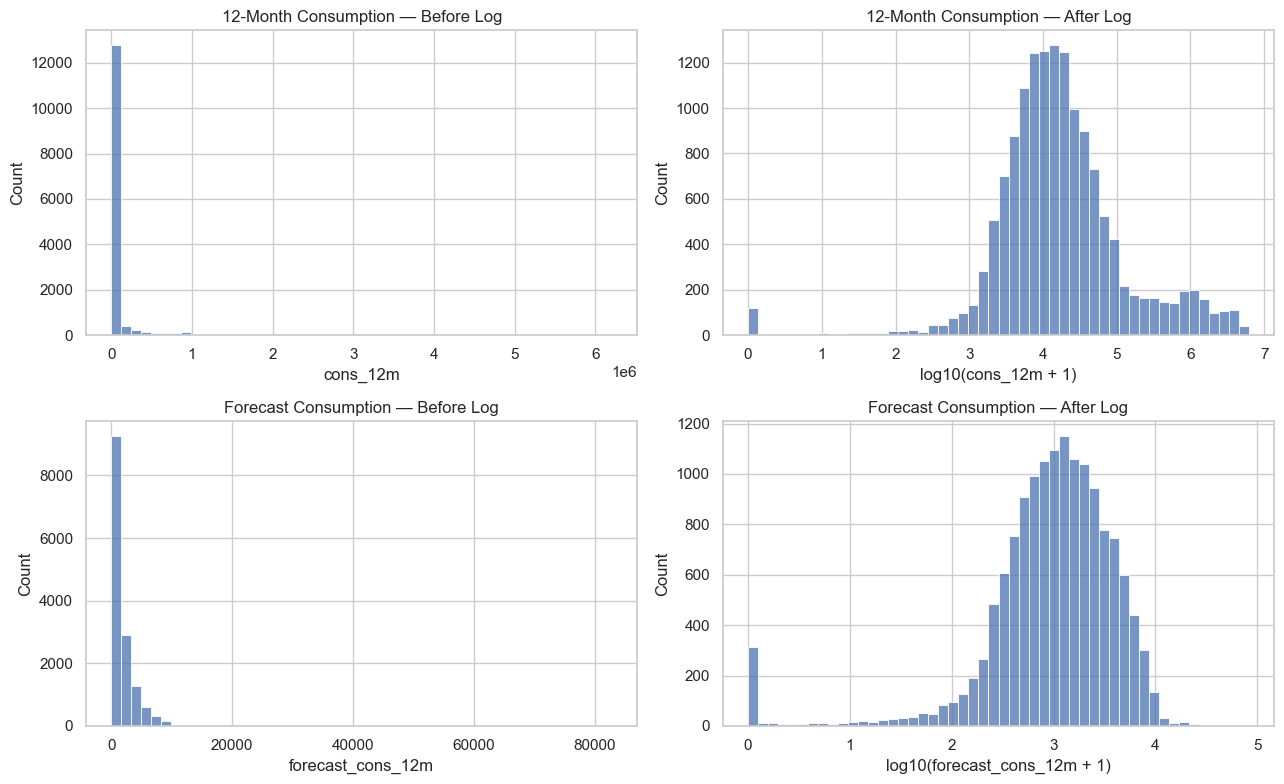

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Create a 2x2 grid for the plots
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# 12-Month Consumption: Before vs After Log
sns.histplot(
    df_model_features["cons_12m"],
    bins=50,
    ax=axes[0, 0]
)
axes[0, 0].set_title("12-Month Consumption — Before Log")
axes[0, 0].set_xlabel("cons_12m")

sns.histplot(
    df_transformed["cons_12m"],
    bins=50,
    ax=axes[0, 1]
)
axes[0, 1].set_title("12-Month Consumption — After Log")
axes[0, 1].set_xlabel("log10(cons_12m + 1)")

# Forecast 12-Month Consumption: Before vs After Log
sns.histplot(
    df_model_features["forecast_cons_12m"],
    bins=50,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Forecast Consumption — Before Log")
axes[1, 0].set_xlabel("forecast_cons_12m")

sns.histplot(
    df_transformed["forecast_cons_12m"],
    bins=50,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Forecast Consumption — After Log")
axes[1, 1].set_xlabel("log10(forecast_cons_12m + 1)")

# Adjust layout and display the plots
plt.tight_layout()
plt.show()

tenure_band  churn_rate  customers
       0–24    0.000000          1
      25–48    0.128668       5316
      49–72    0.082196       6375
      73–96    0.074793       2420
     97–120    0.038168        131
    121–144    0.065868        334
    145–168    0.103448         29


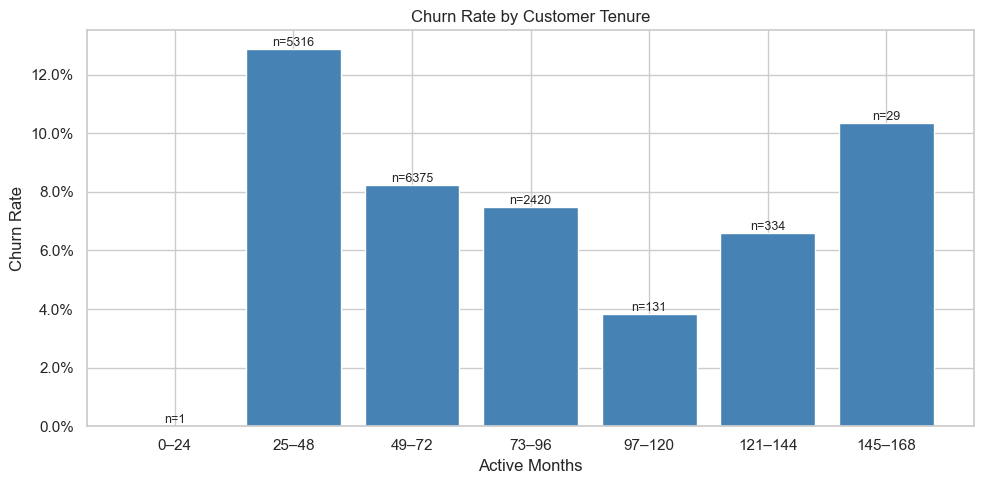

In [43]:
# Visualize the relationship between tenure and churn

from matplotlib.ticker import PercentFormatter

# Group customers by their active months
tenure_data = df_feature_set[["months_activ", "churn"]].dropna().copy()

tenure_bins = [0, 24, 48, 72, 96, 120, 144, 168]
tenure_labels = [
    "0–24", "25–48", "49–72", "73–96",
    "97–120", "121–144", "145–168"
]

tenure_data["tenure_band"] = pd.cut(
    tenure_data["months_activ"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

# Calculate churn rate and total customers for each group
churn_by_tenure = (
    tenure_data.groupby("tenure_band", observed=False)
    .agg(
        churn_rate=("churn", "mean"),
        customers=("churn", "size")
    )
    .reset_index()
)

print(churn_by_tenure.to_string(index=False))

# Plot the churn rate chart
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    churn_by_tenure["tenure_band"].astype(str),
    churn_by_tenure["churn_rate"],
    color="steelblue"
)

ax.set_title("Churn Rate by Customer Tenure")
ax.set_xlabel("Active Months")
ax.set_ylabel("Churn Rate")
ax.yaxis.set_major_formatter(PercentFormatter(1))

# Add the sample size (number of customers) above each bar
for bar, count in zip(bars, churn_by_tenure["customers"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"n={count}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()


  price_change_group  churn_rate  customers
  (-0.149, -0.00841]    0.109284       2919
(-0.00841, -0.00669]    0.108985       2927
(-0.00669, -0.00446]    0.088603       2957
 (-0.00446, -0.0034]    0.090877       2872
    (-0.0034, 0.169]    0.088003       2909


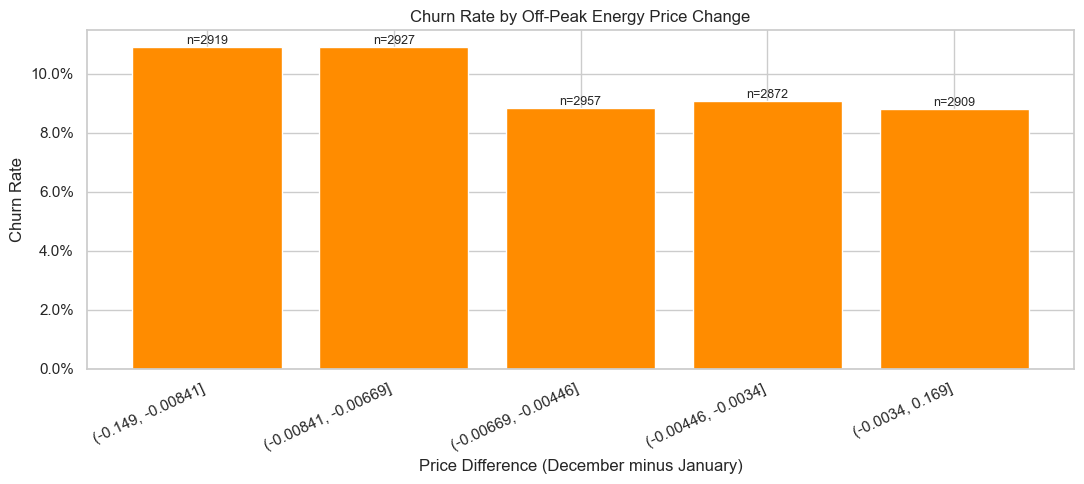

In [44]:
# Test the business hypothesis regarding price changes. Group customers by their January-December off-peak energy price difference and compare churn rates.

price_col = "offpeak_diff_dec_january_energy"

price_data = df_feature_set[[price_col, "churn"]].dropna().copy()

# Group price differences into up to 5 quantile bins
price_data["price_change_group"] = pd.qcut(
    price_data[price_col],
    q=5,
    duplicates="drop"
)

# Calculate churn rate and total customers for each group
churn_by_price_change = (
    price_data.groupby("price_change_group", observed=True)
    .agg(
        churn_rate=("churn", "mean"),
        customers=("churn", "size")
    )
    .reset_index()
)

print(churn_by_price_change.to_string(index=False))

# Plot the churn rate chart
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    churn_by_price_change["price_change_group"].astype(str),
    churn_by_price_change["churn_rate"],
    color="darkorange"
)

ax.set_title("Churn Rate by Off-Peak Energy Price Change")
ax.set_xlabel("Price Difference (December minus January)")
ax.set_ylabel("Churn Rate")
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.xticks(rotation=25, ha="right")

# Add the sample size (number of customers) above each bar
for bar, count in zip(bars, churn_by_price_change["customers"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"n={count}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()


### Visualization findings

The consumption histograms show that the consumption features are strongly right-skewed. Applying a log transformation compresses the large values and makes the distributions easier to inspect, although it does not make every feature normally distributed.

Churn rates vary across customer-tenure groups. The 25–48 month group has the highest rate among the larger groups, while the 97–120 month group has a lower rate. The longest-tenure group contains only 29 customers, so its rate should be interpreted cautiously.

Across the five off-peak energy price-change groups, churn rates range from about 8.8% to 10.9%. The groups with the most negative price changes have the highest rates, but the overall differences are modest. These plots show descriptive associations and do not establish that tenure or price changes cause churn.

#### Feature Engineering Conclusion

The feature engineering process produced a dataset with 14,606 rows and 76 columns. It includes engineered customer tenure and date features, encoded categorical features, price-change features, and additional features comparing forecast and actual consumption.

The raw date columns were removed from the final feature set. date_end was excluded because it could contain information related to churn. Log transformations reduced the skew in several consumption features, although they did not make every feature normally distributed.

Five features still contain missing values: months_renewal (903), last_month_share_of_12m_cons (117), months_modif_prod (61), offpeak_diff_dec_january_energy (22), and offpeak_diff_dec_january_power (22). These values were kept visible rather than removing customer records.

The visualizations show patterns in consumption, customer tenure, and price changes. These are descriptive relationships and do not prove that a feature causes churn. For the modeling task, the stakeholder’s supplied data_for_predictions.csv remains the required dataset.
